# 06. 개선 실험: 입력 해상도(E07)

**가설(H-b, E06에서 구체화)**: 원본 크기 그대로(letterbox 384) 넣으면 가는 바벨이 잘 보여서 **바벨 로우 ↔ 덤벨 로우 혼동이 줄 것이다.** 데드리프트 lockout ↔ 바벨 로우의 선 자세는 자세 자체가 같아서 **해상도로는 크게 나아지지 않을 것이다**(실행 전 예측).

| | 기본(E01·E04) | 해상도 실험(E07a·E07b) |
|---|---|---|
| 원본 384×216을 | 224×126으로 줄임(0.58배) | 그대로(1배) |
| 위아래 패딩 | 49줄씩 → 224×224 | 84줄씩 → 384×384 |
| 픽셀 수 | 50,176 | 147,456(약 2.9배) |

바꾼 것은 입력 크기 하나입니다(증강 없음, 나머지 기본과 같음). 계획과 판정 기준은 실행 전에 `experiments/E07/PLAN.md`에 적었습니다. 판정: Val Macro F1 기본 대비 +0.02 이상 개선, ±0.02 미만 차이 없음, −0.02 이하 악화.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
from common import FIGURES, GROUPS, class_names, set_korean_font
from predict import predict_split

print("font:", set_korean_font())
pd.set_option("display.width", 180)
NAMES = class_names()
PAIRS = [("full", "E04", "E07a"), ("scratch", "E01", "E07b")]
LABEL = {"full": "Full FT", "scratch": "Scratch"}
def load(rid, s):
    d = ROOT / "experiments" / rid / s
    return pd.read_csv(d / "history.csv"), json.loads((d / "summary.json").read_text(encoding="utf-8"))
R = {rid: load(rid, s) for s, b, t in PAIRS for rid in (b, t)}
def verdict(x):
    return "개선" if x >= 0.02 else ("악화" if x <= -0.02 else "차이 없음")

font: Malgun Gothic


## 1. 전체 결과와 비용

In [2]:
rows = []
for s, base, new in PAIRS:
    for rid in (base, new):
        h, sm = R[rid]
        d = sm["val"]["macro_f1"] - R[base][1]["val"]["macro_f1"]
        rows.append({"전략": LABEL[s], "실행": rid, "입력": "384" if rid == new else "224",
                     "Val Macro F1": round(sm["val"]["macro_f1"], 4), "Val Acc": round(sm["val"]["accuracy"], 4),
                     "기본 대비": round(d, 4), "판정": "" if rid == base else verdict(d),
                     "최고/멈춘 epoch": f"{sm['best_epoch']}/{sm['epochs_run']}",
                     "epoch당 학습(초)": round(h.train_time_s.iloc[1:].median(), 1), "총 시간(분)": round(sm["total_time_s"] / 60, 1),
                     "GPU 메모리(MB)": round(sm["peak_gpu_mem_mb"])})
pd.DataFrame(rows)

,전략,실행,입력,Val Macro F1,Val Acc,기본 대비,판정,최고/멈춘 epoch,epoch당 학습(초),총 시간(분),GPU 메모리(MB)
0,Full FT,E04,224,0.8581,0.8660,0.0000,,16/21,9.5,4.4,629
1,Full FT,E07a,384,0.8734,0.9187,0.0153,차이 없음,4/9,23.1,4.3,1365
2,Scratch,E01,224,0.7928,0.7979,0.0000,,9/14,9.5,3.0,629
3,Scratch,E07b,384,0.7485,0.8056,-0.0443,악화,10/15,23.6,7.0,1365


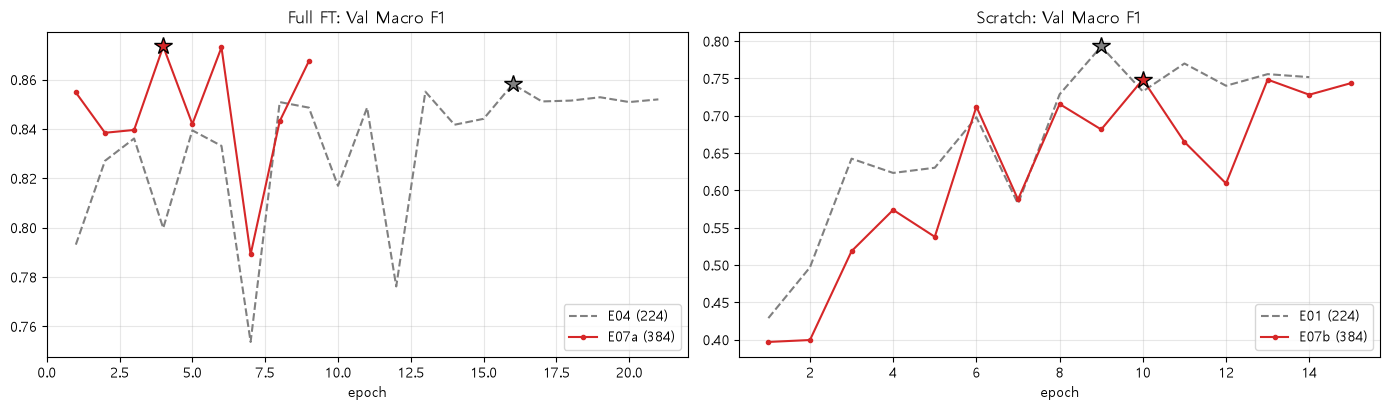

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, (s, base, new) in zip(axes, PAIRS):
    for rid, sty, col in ((base, "--", "gray"), (new, "-", "C3")):
        h, sm = R[rid]
        ax.plot(h.epoch, h.val_macro_f1, sty, color=col, marker="." if rid == new else None, label=f"{rid} ({'384' if rid == new else '224'})")
        ax.plot(sm["best_epoch"], sm["val"]["macro_f1"], "*", ms=13, color=col, mec="k")
    ax.set_title(f"{LABEL[s]}: Val Macro F1"); ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIGURES / "e07_curves.png", dpi=100); plt.show()

## 2. 가설 확인: 혼동 쌍별 장수

가설대로라면 **9↔2(바벨 로우 ↔ 덤벨 로우)는 줄고, 7→9(데드리프트 → 바벨 로우)는 크게 변하지 않아야** 합니다.

In [4]:
rows = []
for s, base, new in PAIRS:
    for rid in (base, new):
        cm = np.array(R[rid][1]["val"]["confusion_matrix"])
        rows.append({"전략": LABEL[s], "실행": rid, "9→2": cm[9, 2], "2→9": cm[2, 9], "9↔2 합": cm[9, 2] + cm[2, 9],
                     "7→9": cm[7, 9], "9→7": cm[9, 7], "7→2": cm[7, 2], "2→7": cm[2, 7],
                     "덤벨 로우 Recall": round(cm[2, 2] / cm[2].sum(), 3), "데드리프트 Recall": round(cm[7, 7] / cm[7].sum(), 3),
                     "바벨 로우 Recall": round(cm[9, 9] / cm[9].sum(), 3)})
pd.DataFrame(rows)

,전략,실행,9→2,2→9,9↔2 합,7→9,9→7,7→2,2→7,덤벨 로우 Recall,데드리프트 Recall,바벨 로우 Recall
0,Full FT,E04,11,21,32,82,13,14,3,0.794,0.400,0.531
1,Full FT,E07a,44,0,44,6,15,18,1,0.969,0.850,0.031
2,Scratch,E01,7,6,13,30,17,53,45,0.512,0.444,0.500
3,Scratch,E07b,8,21,29,39,27,12,23,0.650,0.669,0.219


## 3. 카메라별 정답률(바벨·덤벨 묶음): 무너졌던 칸이 회복됐는가

In [5]:
PRED = {rid: predict_split(rid, s) for s, b, n in PAIRS for rid in (b, n)}
for s, base, new in PAIRS:
    for rid in (base, new):
        b = PRED[rid][PRED[rid].target_id.isin([2, 7, 8, 9])]
        t = b.pivot_table(index="target_id", columns="camera", values="correct", aggfunc="mean").round(2)
        t.index = [f"{c} {NAMES[c]}" for c in t.index]
        print(f"[{rid} {LABEL[s]} 입력 {'384' if rid == new else '224'}] (다시 계산한 Macro F1 {PRED[rid].attrs['macro_f1']:.4f})")
        display(t)

[E04 Full FT 입력 224] (다시 계산한 Macro F1 0.8581)


camera,A,B,C,D,E
2 덤벨 벤트오버 로우,0.72,0.69,1.00,0.85,0.73
7 바벨 데드리프트,0.26,0.24,0.10,0.64,0.69
8 바벨 런지,0.94,0.94,0.85,1.00,1.00
9 바벨 로우,0.80,1.00,0.50,0.00,0.17


[E07a Full FT 입력 384] (다시 계산한 Macro F1 0.8734)


camera,A,B,C,D,E
2 덤벨 벤트오버 로우,0.97,0.97,0.97,1.0,0.94
7 바벨 데드리프트,0.74,0.72,1.00,1.0,0.80
8 바벨 런지,0.86,0.97,0.89,1.0,1.00
9 바벨 로우,0.00,0.00,0.17,0.0,0.00


[E01 Scratch 입력 224] (다시 계산한 Macro F1 0.7928)


camera,A,B,C,D,E
2 덤벨 벤트오버 로우,0.91,0.81,0.90,0.00,0.00
7 바벨 데드리프트,0.00,0.00,0.69,0.76,0.74
8 바벨 런지,0.89,0.66,0.19,0.96,0.97
9 바벨 로우,0.87,0.00,0.00,0.73,0.92


[E07b Scratch 입력 384] (다시 계산한 Macro F1 0.7485)


camera,A,B,C,D,E
2 덤벨 벤트오버 로우,0.12,1.00,0.73,0.82,0.58
7 바벨 데드리프트,0.68,0.66,0.83,0.33,0.86
8 바벨 런지,0.91,0.94,1.00,1.00,1.00
9 바벨 로우,0.40,0.00,0.17,0.36,0.17


## 4. 클래스별 F1 변화(384 − 224)

In [6]:
order = [c for g in GROUPS.values() for c in g]
delta = pd.DataFrame({LABEL[s]: [R[new][1]["val"]["per_class"]["f1"][NAMES[c]] - R[base][1]["val"]["per_class"]["f1"][NAMES[c]] for c in order]
                      for s, base, new in PAIRS}, index=[f"{c} {NAMES[c]}" for c in order]).round(3)
delta

,Full FT,Scratch
0 Y - Exercise,0.053,-0.392
1 니푸쉬업,0.000,0.000
4 라잉 레그 레이즈,0.041,-0.223
10 바이시클 크런치,0.005,-0.285
2 덤벨 벤트오버 로우,0.007,0.241
7 바벨 데드리프트,0.338,0.191
8 바벨 런지,0.020,0.153
9 바벨 로우,-0.281,-0.278
3 딥스,0.000,0.000
5 랫풀 다운,0.000,0.018


## 5. 해석

### 5.1 판정: Full FT는 차이 없음(+0.015), Scratch는 악화(−0.044)

| 실행 | 입력 | Val Macro F1 | 기본 대비 | 판정 | epoch당 학습 | GPU 메모리 |
|---|---|---|---|---|---|---|
| E07a Full FT | 384 | 0.8734 | +0.015 | 차이 없음 | 9.5초 → 23.1초 | 629 → 1,365MB |
| E07b Scratch | 384 | 0.7485 | −0.044 | 악화 | 9.5초 → 23.6초 | 629 → 1,365MB |

미리 정한 기준으로 해상도 384는 채택하지 않습니다. 다만 Full FT의 **내부 변화가 매우 커서** 숫자 하나로 요약하면 안 되는 결과입니다.

### 5.2 실행 전 예측이 틀렸습니다

`PLAN.md`의 예측은 "9↔2(바벨 로우 ↔ 덤벨 로우)는 줄고, 7→9(데드리프트 → 로우)는 그대로"였습니다. 실제는 **반대**였습니다.

| Full FT | 224(E04) | 384(E07a) | 예측 |
|---|---|---|---|
| 7→9 데드리프트 → 로우 | 82 | **6** | 그대로 |
| 데드리프트 Recall | 0.40 | **0.85** | 그대로 |
| 9↔2 합 | 32 | 44 | 줄어듦 |
| 바벨 로우 Recall | 0.53 | **0.03** | 오름 |

- **데드리프트 혼동이 거의 풀렸습니다.** 카메라 A·B·C(뒤·정면)의 정답률이 0.10~0.26에서 0.72~1.00으로 올랐습니다. E06에서 "선 자세(lockout)는 자세 자체가 같으니 해상도로는 어렵다"고 봤는데, 크게 본 사진에는 두 운동을 가르는 단서가 있었다는 뜻입니다. 무엇이 단서인지(그립 너비, 바벨과 원판, 다리 모양 등)는 이 실험만으로는 알 수 없습니다.
- **대신 바벨 로우를 거의 통째로 잃었습니다**(64장 중 2장만 맞힘). 44장은 덤벨 로우, 15장은 데드리프트로 예측했습니다. 덤벨 로우 → 바벨 로우(2→9)는 21장에서 0장이 되었습니다. 모델이 "바벨 로우"라는 답을 거의 내지 않게 된 것입니다.
- 오류 분석에서 세운 원인 판단이 실험으로 뒤집힐 수 있다는 좋은 예입니다. 그래서 E06 결론을 "관찰 기반 가설"로 적었습니다.

### 5.3 Accuracy와 Macro F1이 다르게 움직인 이유

- Full FT의 Val Accuracy는 0.866 → **0.919**(+5.3%p)로 크게 올랐는데, Macro F1은 +0.015에 그쳤습니다.
- 데드리프트(160장)를 많이 맞히게 된 대신, 바벨 로우(64장)를 잃었기 때문입니다. Accuracy는 장수가 많은 데드리프트의 이득을 크게 반영합니다. Macro F1은 바벨 로우 F1이 0에 가까워진 손실을 12분의 1만큼 그대로 반영합니다.
- 02 노트북 4절에서 가상 예시로 설명한 일이 실제로 일어났습니다. "모든 운동을 고르게 맞히는가"가 목표라서, 이 결과를 "개선"이라고 하지 않습니다.

### 5.4 바벨 로우가 계속 희생됩니다

- 바벨 로우가 통째로 사라진 실행이 이번이 세 번째입니다.
  - Scratch + 증강(E05a·E05e): Recall 0.00
  - Partial + 증강(E05c): 0.03
  - Full 384(E07a): 0.03
- 모델이 무언가를 새로 잘하게 되면, 가장 적은 클래스(Train 312장, 다른 클래스의 절반 이하)인 바벨 로우가 그 대가를 치르는 패턴입니다.
- Val의 바벨 로우는 64장(8클립, Z23 한 사람)뿐이고, Train에 드문 특이 자세(바벨을 가슴·머리 높이로 든 프레임)도 섞여 있습니다. 이 클래스의 수치는 특히 흔들리기 쉽습니다.
- → 다음 개선 실험 후보로 **클래스 가중치**(적은 클래스의 손실을 키움)의 근거가 더 강해졌습니다.

### 5.5 Scratch는 해상도를 올리자 나빠졌습니다

- 바벨·덤벨 묶음(덤벨 로우 +0.24, 데드리프트 +0.19)은 좋아졌지만, 맨몸 묶음이 크게 나빠졌습니다(Y-Exercise −0.39, 바이시클 크런치 −0.29, 라잉 레그 레이즈 −0.22).
- 최고 시점 Train Accuracy는 0.970으로 기본(0.952)보다 더 외웠고, Val 곡선도 크게 출렁였습니다(0.61~0.75).
- 사전학습 없이 큰 입력을 받으면 바닥·배경의 세부까지 외울 거리가 늘어난다는 해석이 가능합니다(가설). 사전학습 특징이 있는 Full FT는 같은 변화에서 무너지지 않았습니다.

### 5.6 비용

해상도 384는 epoch당 약 2.4배(9.5 → 23초), GPU 메모리 약 2.2배(629 → 1,365MB)입니다. Full FT는 일찍(4 epoch) 최고점에 닿아서 총 시간은 기본과 비슷했습니다(4.4 → 4.3분).

### 5.7 다음 단계

1. **클래스 가중치**: 바벨 로우가 반복해서 희생되는 문제를 겨냥합니다. 224와 384 중 어디에 적용할지는 사용자와 정합니다(한 요인씩이라 기본 224 위에 하는 것이 원칙).
2. **전처리 방법 비교 시리즈**(늘려 맞추기, 가운데 자르기, 패딩 없는 384×216): 패딩 실험과 질문이 달라서 따로 묶습니다.
3. **최종 선정(U-12)**: 이제 가장 높은 Val Macro F1은 E07a(0.873)입니다. 하지만 바벨 로우를 거의 맞히지 못합니다(D-015의 "클래스별 Recall이 크게 무너진 모델은 제외하고 이유를 쓴다"에 해당). 최종 선정 규칙을 정할 때 함께 다룹니다.